In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score

sns.set_theme(style="whitegrid", context="notebook")

In [ ]:
df = pd.read_csv("./data_20230430.csv")
df.columns = ["character_chosen", "least_favorite", "favorite_item", 
              "least_favorite_item", "favorite_track", 
              "least_favorite_track", "prefer_to_play_alone",
              "worried_of_red_shells", "love_Mario_Kart_parties",
              "get_road_rage", "have_time_to_play", "mix_courses",
              "competitive","tatical", "best_driver", "celebrate_loudly",
              "team_matches","love_the_music", "people_target_me",
              "simpathy_for_spiny_shells", "upset_if_I_loose", 
              "just_happy_to_be_involved", "welcoming_person_to_play",
              "only_play_with_favorite_character", "involve_everyone",
              "cheer_others_if_winning", "cheat"
              ]


In [5]:
print(df.shape)
df.head()

(125, 27)


,character_chosen,least_favorite,favorite_item,least_favorite_item,favorite_track,least_favorite_track,prefer_to_play_alone,worried_of_red_shells,love_Mario_Kart_parties,get_road_rage,...,love_the_music,people_target_me,simpathy_for_spiny_shells,upset_if_I_loose,just_happy_to_be_involved,welcoming_person_to_play,only_play_with_favorite_character,involve_everyone,cheer_others_if_winning,cheat
0,Bowser,Lakitu,Red Shell,Bomerang Flower,Mario Kart Stadium,N64 Rainbow Road,1,4,5,5,...,3,5,4,4,2,5,1,3,4,1
1,Yoshi,Bowser,Bullet Bill,Banana,Sweet Sweet Canyon,Rainbow Road,1,2,5,4,...,4,4,2,4,2,2,1,4,2,1
2,Toad,Donkey Kong,Red Shell,Banana,Shy Guy Falls,Sunshine Airport,1,2,5,4,...,3,1,2,2,4,5,1,4,5,2
3,Bowser,Inkling Girl,Green Shell,Spiny Shell,Mount Wario,Dolphin Shoals,1,2,5,1,...,4,4,5,1,3,4,5,4,4,1
4,Toad,Koopa Trooper,Lightning,Bomb-omb,Rainbow Road,Bowser's Castle,1,3,5,5,...,4,2,1,3,4,4,2,3,4,1


In [6]:
df = df.drop_duplicates()
print(df.shape)

(125, 27)


In [41]:
print(df["character_chosen"].value_counts())

character_chosen
Yoshi              27
Toad               15
Peach              13
Luigi               6
Bowser              5
Waluigi             5
King Boo            5
Donkey Kong         5
Mario               5
Daisy               4
Dry Bones           4
Shy Guy             4
Rosalina            4
Cat Peach           3
Tanooki Mario       3
Koopa Troopa        2
Pink Gold Peach     2
Wario               2
Isabelle            1
Dry Bowser          1
Roy                 1
Link                1
Baby Luigi          1
Birdo               1
Ludwig              1
Iggy                1
Bowser Jr.          1
Lemmy               1
Morton              1
Name: count, dtype: int64


In [15]:
print(df["character_chosen"].unique())
print(df["least_favorite"].unique())
print(df["favorite_item"].unique())
print(df["least_favorite_item"].unique())
print(df["favorite_track"].unique())
print(df["least_favorite_track"].unique())


<StringArray>
[         'Bowser',           'Yoshi',            'Toad',         'Waluigi',
           'Peach',           'Luigi',           'Daisy',        'Isabelle',
        'King Boo',     'Donkey Kong',       'Dry Bones',       'Cat Peach',
           'Mario',    'Koopa Troopa',   'Tanooki Mario',      'Dry Bowser',
         'Shy Guy',        'Rosalina', 'Pink Gold Peach',             'Roy',
            'Link',      'Baby Luigi',           'Birdo',          'Ludwig',
            'Iggy',           'Wario',      'Bowser Jr.',           'Lemmy',
          'Morton']
Length: 29, dtype: str
<StringArray>
[         'Lakitu',          'Bowser',     'Donkey Kong',    'Inkling Girl',
   'Koopa Trooper',     'Metal Mario',         'Waluigi',      'Baby Peach',
           'Peach',           'Daisy',           'Wario',     'Inkling Boy',
 'Villager Female',           'Yoshi',           'Luigi',           'Mario',
      'Baby Luigi',            'Link',             'Mii',       'Dry Bones',
     

In [34]:
numerical_features = ["prefer_to_play_alone",
              "worried_of_red_shells", "love_Mario_Kart_parties",
              "get_road_rage", "have_time_to_play", "mix_courses",
              "competitive","tatical", "best_driver", "celebrate_loudly",
              "team_matches","love_the_music", "people_target_me",
              "simpathy_for_spiny_shells", "upset_if_I_loose", 
              "just_happy_to_be_involved", "welcoming_person_to_play",
              "only_play_with_favorite_character", "involve_everyone",
              "cheer_others_if_winning", "cheat"
              ]

categorical_features = [ "least_favorite",
                        "favorite_item", "least_favorite_item",
                        "favorite_track", "least_favorite_track"]

df_encoded = pd.get_dummies(df, columns=categorical_features, drop_first=True, dtype=int)


In [35]:

print(df_encoded.shape)

(125, 143)


In [36]:
df_encoded.head()

,character_chosen,prefer_to_play_alone,worried_of_red_shells,love_Mario_Kart_parties,get_road_rage,have_time_to_play,mix_courses,competitive,tatical,best_driver,...,least_favorite_track_SNES Donut Plains 3,least_favorite_track_Shy Guy Falls,least_favorite_track_Sunshine Airport,least_favorite_track_Sweet Sweet Canyon,least_favorite_track_Thwomp Ruins,least_favorite_track_Toad Harbour,least_favorite_track_Twisted Mansion,least_favorite_track_Water Park,least_favorite_track_Wii Grumble Volcano,least_favorite_track_Wii Moo Moo Meadows
0,Bowser,1,4,5,5,4,5,5,5,4,...,0,0,0,0,0,0,0,0,0,0
1,Yoshi,1,2,5,4,5,4,5,4,2,...,0,0,0,0,0,0,0,0,0,0
2,Toad,1,2,5,4,2,5,5,5,4,...,0,0,1,0,0,0,0,0,0,0
3,Bowser,1,2,5,1,2,5,2,4,4,...,0,0,0,0,0,0,0,0,0,0
4,Toad,1,3,5,5,2,5,5,4,2,...,0,0,0,0,0,0,0,0,0,0


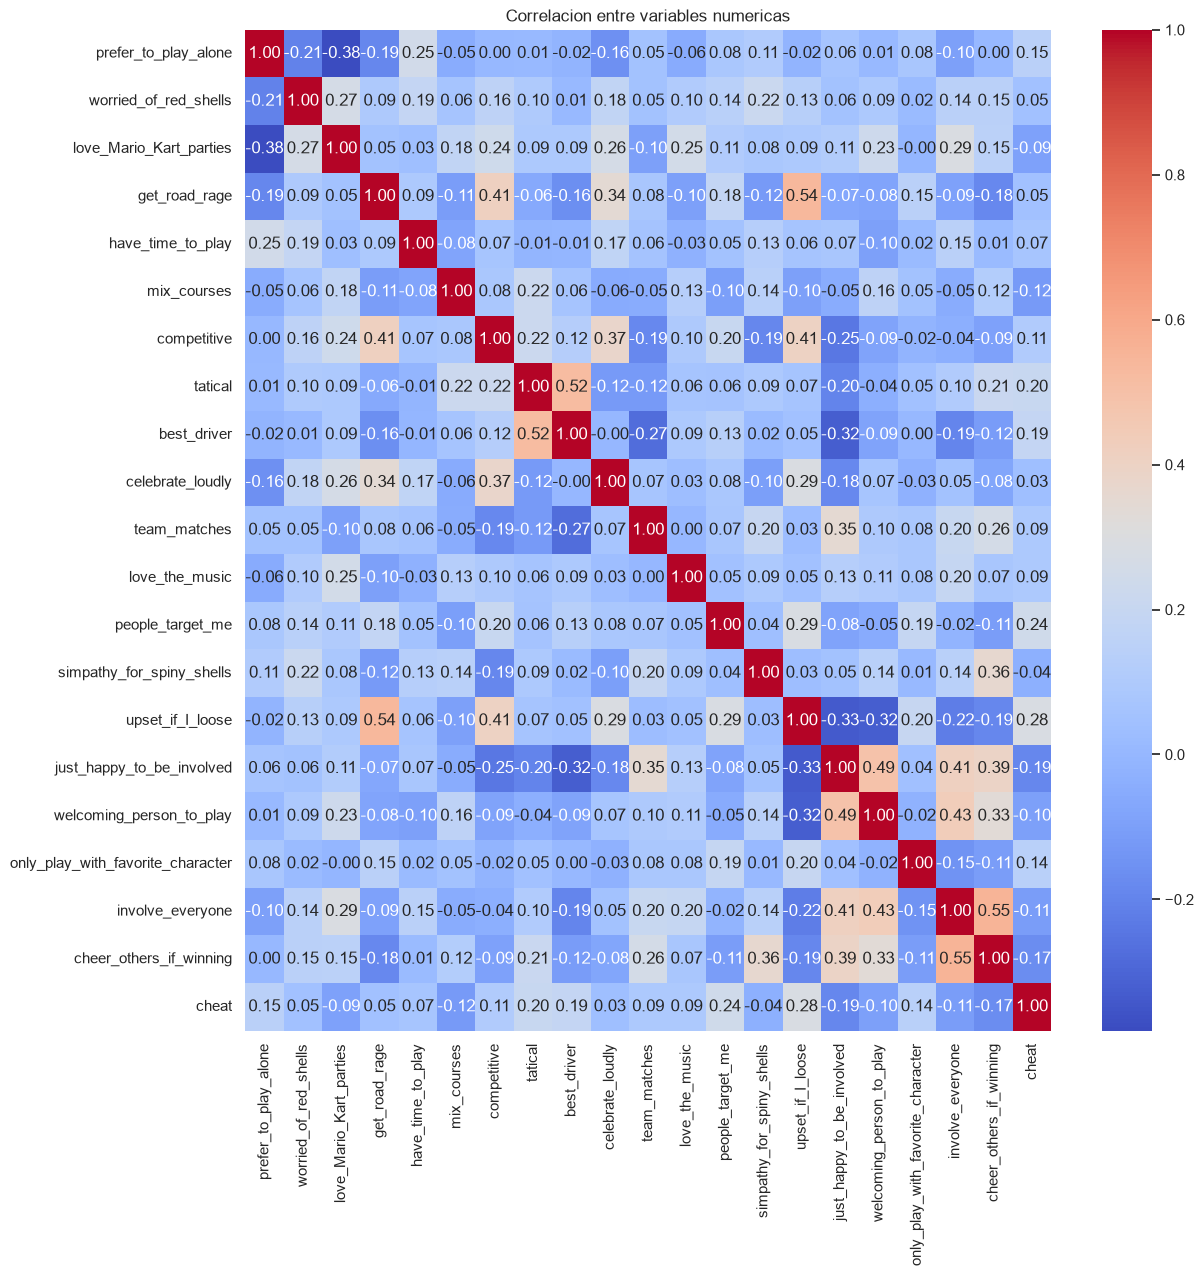

In [37]:
plt.figure(figsize=(13, 13))
sns.heatmap(df[numerical_features].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlacion entre variables numericas")
plt.show()

In [40]:
X = df_encoded.drop(columns=["character_chosen"])
y = df_encoded["character_chosen"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

ValueError: The least populated classes in y have only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2. Classes with too few members are: ['Baby Luigi', 'Birdo', 'Bowser Jr.', 'Dry Bowser', 'Iggy', 'Isabelle', 'Lemmy', 'Link', 'Ludwig', 'Morton', 'Roy']